In [ ]:
!pip install -q binance_historical_data


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.8/272.8 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 34.6 MB/s eta 0:00:00



##############################################################################
#  CRYPTO QUANT STRATEGY — Top 10 Market Cap Portfolio
#  Target: Sharpe > 1.0  &  MaxDD > -30%
##############################################################################

[1/4] Downloading 1h data for 10 tickers...
---> Found overall tickers: 712
---> Filter to asked tickers: 10
------> Tickers left: 10
Download full data for 10 tickers: 
---> Data will be saved here: /content/crypto_data/um
---> Data Frequency: 1h
---> Start Date: 20200101
---> End Date: 20260101


Tickers:   0%|          | 0/10 [00:00<?, ?it/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

...

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 10 tickers:
---> For BTCUSDT new data saved for: 0 months 0 days
---> For ETHUSDT new data saved for: 0 months 0 days
---> For XRPUSDT new data saved for: 0 months 0 days
---> For TRXUSDT new data saved for: 0 months 0 days
---> For LINKUSDT new data saved for: 0 months 0 days
---> For ADAUSDT new data saved for: 0 months 0 days
---> For BNBUSDT new data saved for: 0 months 0 days
---> For DOGEUSDT new data saved for: 0 months 0 days
---> For SOLUSDT new data saved for: 0 months 0 days
---> For AVAXUSDT new data saved for: 0 months 0 days

[2/4] Loading data...
  BTCUSDT      52632 bars  [2020-01-01 → 2026-01-01]
  ETHUSDT      52632 bars  [2020-01-01 → 2026-01-01]
  XRPUSDT      52384 bars  [2020-01-06 → 2026-01-01]
  BNBUSDT      51664 bars  [2020-02-10 → 2026-01-01]
  SOLUSDT      46337 bars  [2020-09-14 → 2026-01-01]
  DOGEUSDT     48039 bars  [2020-07-10 → 2026-01-01]
  TRXUSDT      52168 bars  [2020-01-15 → 2026-01-01]
  ADAUSDT      51904 bars  [2020-01-31

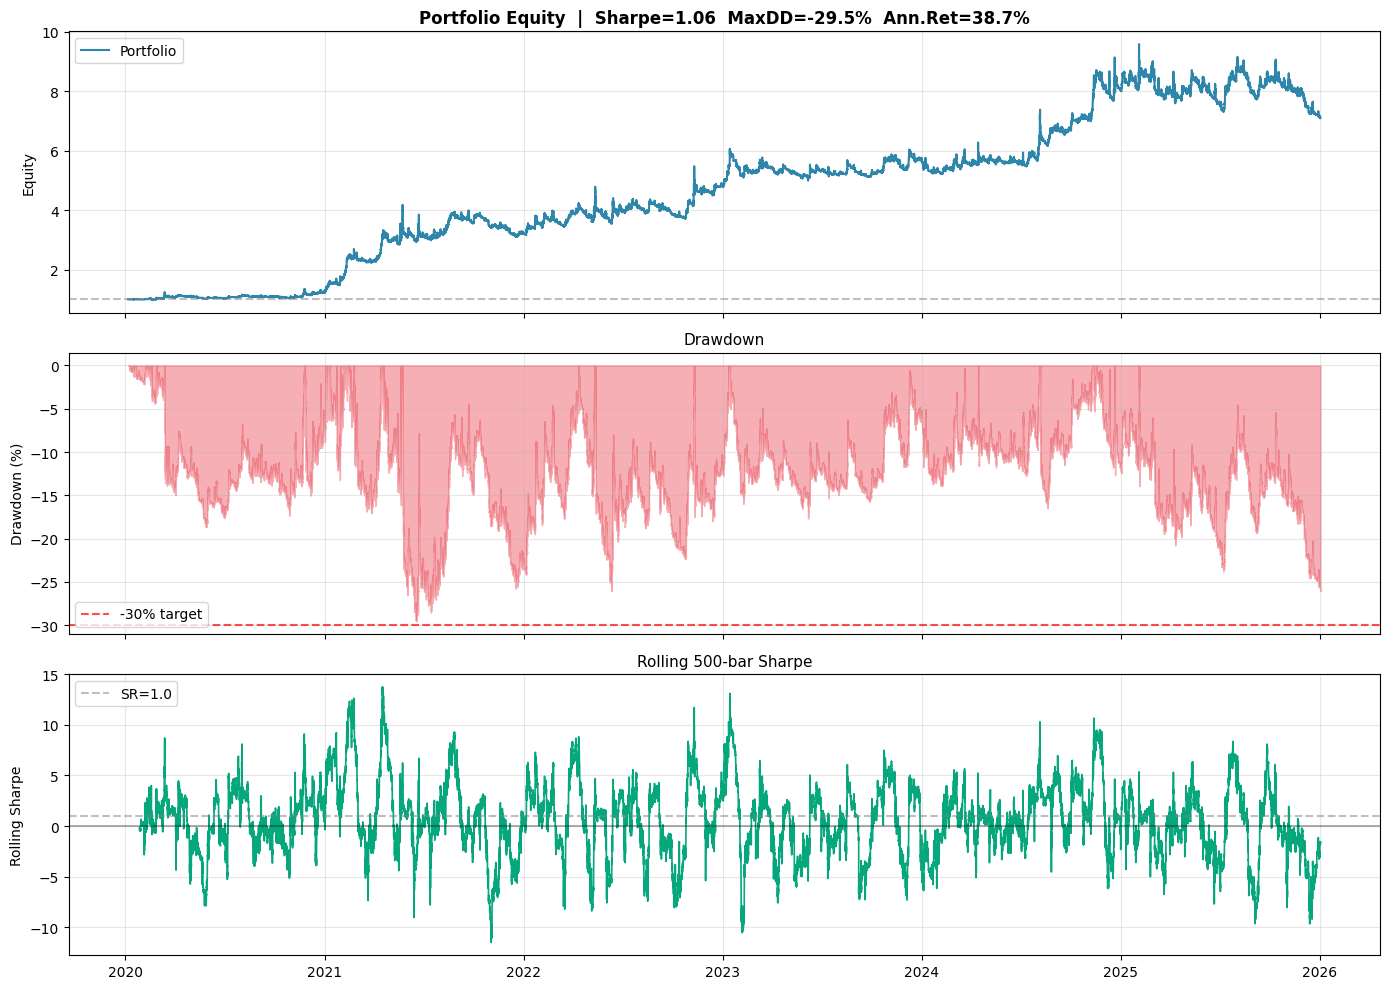


💾 Saved: equity_curve.csv, asset_summary.csv


In [ ]:
"""
================================================================================
CRYPTO QUANT STRATEGY — Top 10 Market Cap Portfolio
================================================================================

Assignment requirements:
  - Universe: Top 10 cryptocurrencies by market cap
  - Data:     5 years of historical data (2020-01-01 to 2026-01-01)
  - Target:   Sharpe Ratio > 1.0
  - Target:   Max Drawdown > -30%

Strategy overview:
  1. Download hourly OHLCV data from Binance USDT-M futures
  2. Generate 11 directional alphas (momentum, trend, breakout)
  3. For each asset, select top-N alphas by train Sharpe
  4. Build equal-weight composite signal, EMA-smoothed
  5. Backtest with stop-loss and transaction costs
  6. Equal-weight 10 assets, apply portfolio-level leverage
  7. Evaluate with train/test split for OOS validation

Author:  Pham Long Vu
Repo:    https://github.com/Zusphamm/quant-binance-research
================================================================================
"""

from __future__ import annotations

import os
import sys
import warnings
from datetime import datetime
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

try:
    from binance_historical_data import BinanceDataDumper
except ImportError:
    print("Installing binance_historical_data...")
    os.system(f"{sys.executable} -m pip install -q binance_historical_data")
    from binance_historical_data import BinanceDataDumper


# ──────────────────────────────────────────────────────────────────────────────
# CONFIGURATION
# ──────────────────────────────────────────────────────────────────────────────

CONFIG = {
    "universe": [
        "BTCUSDT", "ETHUSDT", "XRPUSDT", "BNBUSDT", "SOLUSDT",
        "DOGEUSDT", "TRXUSDT", "ADAUSDT", "AVAXUSDT", "LINKUSDT",
    ],

    "frequency":  "1h",
    "start_date": "2020-01-01",
    "end_date":   "2026-01-01",
    "market":     "um",
    "data_dir":   "./crypto_data",

    "train_test_split": 0.6,
    "fee_bps":          6.0,
    "stop_loss":        0.09,

    "n_top_alphas":       10,
    "signal_smooth":      48,
    "entry_threshold":    0.3,
    "portfolio_leverage": 0.72,
    "min_asset_train_sr": 0.5,        # Mới

}


# ──────────────────────────────────────────────────────────────────────────────
# DATA LOADER
# ──────────────────────────────────────────────────────────────────────────────

def download_data(tickers, start, end, frequency="1h", market="um", data_dir="./crypto_data"):
    os.makedirs(data_dir, exist_ok=True)
    dumper = BinanceDataDumper(
        path_dir_where_to_dump=data_dir,
        asset_class=market,
        data_type="klines",
        data_frequency=frequency,
    )
    dumper.dump_data(
        tickers=tickers,
        date_start=datetime.strptime(start, "%Y-%m-%d").date(),
        date_end=datetime.strptime(end, "%Y-%m-%d").date(),
        is_to_update_existing=False,
    )


def _detect_ts_unit(ts):
    n = len(str(int(ts)))
    return "ms" if n == 13 else "us"


def _read_csv(path):
    with open(path) as f:
        first_line = f.readline().strip().lower()
    has_header = "open_time" in first_line or "open time" in first_line

    df = pd.read_csv(path, header=0 if has_header else None)

    if not has_header:
        df.columns = [
            "open_time", "open", "high", "low", "close", "volume",
            "close_time", "quote_volume", "n_trades",
            "taker_buy_base", "taker_buy_quote", "ignore",
        ]
    else:
        df.columns = [c.lower().replace(" ", "_") for c in df.columns]

    try:
        unit = _detect_ts_unit(df["open_time"].iloc[0])
        df["open_time"] = pd.to_datetime(df["open_time"], unit=unit, errors="coerce")
    except Exception:
        df["open_time"] = pd.to_datetime(df["open_time"], errors="coerce")

    keep = ["open_time", "open", "high", "low", "close", "volume"]
    df = df[[c for c in keep if c in df.columns]]
    df = df.dropna(subset=["open_time"])

    for col in ["open", "high", "low", "close", "volume"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df.dropna()


def load_ticker(ticker, frequency="1h", market="um", data_dir="./crypto_data"):
    base = os.path.join(data_dir, "futures", market) if market in ("um", "cm") \
           else os.path.join(data_dir, market)
    daily_dir = os.path.join(base, "daily", "klines", ticker, frequency)
    monthly_dir = os.path.join(base, "monthly", "klines", ticker, frequency)

    files = []
    for d in [daily_dir, monthly_dir]:
        if os.path.exists(d):
            files.extend([os.path.join(d, f) for f in os.listdir(d) if f.endswith(".csv")])

    if not files:
        return pd.DataFrame()

    dfs = [_read_csv(f) for f in files]
    df = pd.concat(dfs, ignore_index=True)
    df = df.drop_duplicates(subset=["open_time"]).sort_values("open_time").reset_index(drop=True)
    df = df.set_index("open_time")
    return df


# ──────────────────────────────────────────────────────────────────────────────
# ALPHA LIBRARY — 11 directional alphas
# ──────────────────────────────────────────────────────────────────────────────
# See STRATEGY_EXPLANATION.md for the rationale behind using multiple alphas.

def _safe(x):
    return x.replace([np.inf, -np.inf], np.nan).fillna(0)


def alpha_mom_20(c, **kw):
    return c.pct_change(20).rename("mom_20")

def alpha_mom_60(c, **kw):
    return c.pct_change(60).rename("mom_60")

def alpha_mom_120(c, **kw):
    return c.pct_change(120).rename("mom_120")

def alpha_risk_adj_mom(c, **kw):
    ret = c.pct_change(60)
    vol = c.pct_change().rolling(60).std().replace(0, np.nan)
    return (ret / vol).rename("risk_adj_mom")

def alpha_decay_mom(c, **kw):
    ret = c.pct_change()
    w = np.exp(np.linspace(-3, 0, 60))
    w /= w.sum()
    return ret.rolling(60).apply(lambda x: np.dot(x, w), raw=True).rename("decay_mom")

def alpha_ema_cross(c, **kw):
    fast = c.ewm(span=20, adjust=False).mean()
    slow = c.ewm(span=60, adjust=False).mean()
    return (fast / slow - 1).rename("ema_cross")

def alpha_ema_long(c, **kw):
    fast = c.ewm(span=50, adjust=False).mean()
    slow = c.ewm(span=200, adjust=False).mean()
    return (fast / slow - 1).rename("ema_long")

def alpha_macd(c, **kw):
    fast = c.ewm(span=12, adjust=False).mean()
    slow = c.ewm(span=26, adjust=False).mean()
    macd = fast - slow
    signal = macd.ewm(span=9, adjust=False).mean()
    return (macd - signal).rename("macd_hist")

def alpha_multi_ema(c, **kw):
    s = (np.sign(c - c.ewm(span=20).mean())
       + np.sign(c - c.ewm(span=50).mean())
       + np.sign(c - c.ewm(span=100).mean()))
    return s.rename("multi_ema")

def alpha_donchian(c, h, l, **kw):
    hi = h.rolling(40).max()
    lo = l.rolling(40).min()
    return ((c - (hi + lo) / 2) / (hi - lo).replace(0, np.nan)).rename("donchian")

def alpha_channel_50(c, h, l, **kw):
    hi = h.rolling(100).max()
    lo = l.rolling(100).min()
    return ((c - lo) / (hi - lo).replace(0, np.nan) - 0.5).rename("channel_50")


ALPHA_REGISTRY = [
    alpha_mom_20, alpha_mom_60, alpha_mom_120, alpha_risk_adj_mom, alpha_decay_mom,
    alpha_ema_cross, alpha_ema_long, alpha_macd, alpha_multi_ema,
    alpha_donchian, alpha_channel_50,
]


def generate_alphas(df):
    kw = {"c": df["close"], "o": df["open"], "h": df["high"],
          "l": df["low"], "v": df["volume"]}
    sigs = {}
    for fn in ALPHA_REGISTRY:
        try:
            result = fn(**kw)
            sigs[result.name] = _safe(result)
        except Exception:
            pass
    return pd.DataFrame(sigs, index=df.index)


# ──────────────────────────────────────────────────────────────────────────────
# BACKTESTER
# ──────────────────────────────────────────────────────────────────────────────

def backtest(signal, returns, fee_bps=6.0, stop_loss=0.09,
             entry_threshold=0.3, periods_per_year=365.25*24):
    df = pd.DataFrame({"signal": signal, "ret": returns}).dropna()
    if len(df) < 100:
        return _empty_result()

    std = df["signal"].rolling(200, min_periods=50).std().replace(0, np.nan)
    pos = (df["signal"] / std).clip(-2, 2) / 2
    pos = pos.where(pos.abs() >= entry_threshold, 0.0)
    pos = pos.shift(1).fillna(0)

    pos_array = pos.values.copy()
    rets_array = df["ret"].values
    trade_pnl = 0.0

    for i in range(1, len(pos_array)):
        if np.sign(pos_array[i]) != np.sign(pos_array[i-1]) and pos_array[i-1] != 0:
            trade_pnl = 0.0
        if pos_array[i] != 0:
            trade_pnl += pos_array[i] * rets_array[i]
            if trade_pnl <= -stop_loss:
                pos_array[i] = 0
                trade_pnl = 0.0

    pos = pd.Series(pos_array, index=df.index)

    gross = pos * df["ret"]
    turnover = pos.diff().abs().fillna(0)
    cost = turnover * (fee_bps / 10_000)
    net = gross - cost

    cum = (1 + net).cumprod()
    sharpe = (net.mean() / net.std() * np.sqrt(periods_per_year)) if net.std() > 0 else 0
    ann_ret = cum.iloc[-1] ** (periods_per_year / len(net)) - 1 if len(net) > 0 else 0
    peak = cum.cummax()
    dd = cum / peak - 1
    max_dd = dd.min()
    calmar = ann_ret / abs(max_dd) if max_dd < 0 else 0

    win_rate = (net[pos != 0] > 0).mean() if (pos != 0).any() else 0

    split = int(len(net) * 0.6)
    train_sr = (net.iloc[:split].mean() / net.iloc[:split].std() * np.sqrt(periods_per_year)
                if net.iloc[:split].std() > 0 else 0)
    test_sr = (net.iloc[split:].mean() / net.iloc[split:].std() * np.sqrt(periods_per_year)
               if net.iloc[split:].std() > 0 else 0)

    return {
        "pnl": net, "cumulative": cum, "positions": pos, "drawdown": dd,
        "sharpe": sharpe, "annual_return": ann_ret, "max_drawdown": max_dd,
        "calmar": calmar, "win_rate": win_rate,
        "train_sharpe": train_sr, "test_sharpe": test_sr,
        "n_trades": int((turnover > 0).sum()),
    }


def _empty_result():
    return {
        "pnl": pd.Series(dtype=float), "cumulative": pd.Series(dtype=float),
        "positions": pd.Series(dtype=float), "drawdown": pd.Series(dtype=float),
        "sharpe": 0, "annual_return": 0, "max_drawdown": 0, "calmar": 0,
        "win_rate": 0, "train_sharpe": 0, "test_sharpe": 0, "n_trades": 0,
    }


# ──────────────────────────────────────────────────────────────────────────────
# ALPHA SELECTION & COMPOSITE
# ──────────────────────────────────────────────────────────────────────────────

def select_top_alphas(signals_df, returns, n_top=10, fee_bps=6.0, stop_loss=0.09):
    results = []
    for col in signals_df.columns:
        r = backtest(signals_df[col], returns, fee_bps=fee_bps, stop_loss=stop_loss)
        results.append({
            "alpha": col,
            "train_sharpe": r["train_sharpe"],
            "test_sharpe": r["test_sharpe"],
            "sharpe": r["sharpe"],
        })
    summary = pd.DataFrame(results).sort_values("train_sharpe", ascending=False).reset_index(drop=True)
    top = summary.head(n_top)["alpha"].tolist()
    return top, summary


def build_composite_signal(signals_df, top_alphas, smooth_span=48):
    weights = np.ones(len(top_alphas)) / len(top_alphas)

    normalized = []
    for alpha in top_alphas:
        x = signals_df[alpha]
        mean = x.rolling(500, min_periods=50).mean()
        std = x.rolling(500, min_periods=50).std().replace(0, np.nan)
        z = (x - mean) / std
        normalized.append(z.clip(-3, 3))

    composite = sum(w * s for w, s in zip(weights, normalized))
    composite = composite.ewm(span=smooth_span, adjust=False).mean()
    return composite.rename("composite")


# ──────────────────────────────────────────────────────────────────────────────
# PORTFOLIO CONSTRUCTION
# ──────────────────────────────────────────────────────────────────────────────

def build_portfolio(asset_data, cfg):
    periods_per_year = 365.25 * 24 if cfg["frequency"] == "1h" else 365.25 * 6

    print(f"\n{'='*78}")
    print("BUILDING STRATEGY PER ASSET")
    print(f"{'='*78}\n")

    asset_signals = {}
    per_asset_summary = []

    for ticker, df in asset_data.items():
        if df.empty or len(df) < 500:
            print(f"  {ticker}: SKIP (insufficient data)")
            continue

        returns = df["close"].pct_change()
        signals = generate_alphas(df)

        top_alphas, _ = select_top_alphas(
            signals, returns,
            n_top=cfg["n_top_alphas"],
            fee_bps=cfg["fee_bps"],
            stop_loss=cfg["stop_loss"],
        )

        composite = build_composite_signal(
            signals, top_alphas,
            smooth_span=cfg["signal_smooth"],
        )

        result = backtest(
            composite, returns,
            fee_bps=cfg["fee_bps"],
            stop_loss=cfg["stop_loss"],
            entry_threshold=cfg["entry_threshold"],
            periods_per_year=periods_per_year,
        )

        asset_signals[ticker] = composite

        per_asset_summary.append({
            "asset": ticker,
            "sharpe": result["sharpe"],
            "train_sr": result["train_sharpe"],
            "test_sr": result["test_sharpe"],
            "max_dd": result["max_drawdown"],
            "win_rate": result["win_rate"],
            "n_trades": result["n_trades"],
        })

        print(f"  {ticker:10s}  SR={result['sharpe']:6.3f}  "
              f"OOS_SR={result['test_sharpe']:6.3f}  "
              f"MDD={result['max_drawdown']:7.2%}  "
              f"WR={result['win_rate']:.1%}")

    print(f"\n{'='*78}")
    print("PORTFOLIO AGGREGATION (equal-weight across assets)")
    print(f"{'='*78}\n")

    # Filter assets by train Sharpe — only keep assets with decent in-sample edge
    min_train_sr = cfg.get("min_asset_train_sr", 0.5)
    good_assets = [
        row["asset"] for row in per_asset_summary
        if row["train_sr"] >= min_train_sr
    ]
    print(f"  Filtered to {len(good_assets)} assets with train_sr >= {min_train_sr}: {good_assets}")

    pnl_df = pd.DataFrame()
    for ticker in good_assets:
        sig = asset_signals[ticker]
        df = asset_data[ticker]
        ret = df["close"].pct_change()
        result = backtest(
            sig, ret,
            fee_bps=cfg["fee_bps"],
            stop_loss=cfg["stop_loss"],
            entry_threshold=cfg["entry_threshold"],
            periods_per_year=periods_per_year,
        )
        pnl_df[ticker] = result["pnl"]

    pnl_df = pnl_df.fillna(0)

    if pnl_df.empty or pnl_df.shape[1] == 0:
        print("❌ No assets loaded. Check data directory.")
        return {
            "portfolio_pnl": pd.Series(dtype=float),
            "portfolio_cum": pd.Series(dtype=float),
            "portfolio_dd": pd.Series(dtype=float),
            "asset_pnls": pnl_df,
            "asset_summary": pd.DataFrame(per_asset_summary),
            "sharpe": 0, "annual_return": 0, "max_drawdown": 0, "calmar": 0,
            "train_sharpe": 0, "test_sharpe": 0, "n_assets": 0,
        }

    n_assets = len(pnl_df.columns)
    portfolio_pnl = pnl_df.mean(axis=1) * cfg["portfolio_leverage"]

    cum = (1 + portfolio_pnl).cumprod()
    sharpe = portfolio_pnl.mean() / portfolio_pnl.std() * np.sqrt(periods_per_year)
    ann_ret = cum.iloc[-1] ** (periods_per_year / len(portfolio_pnl)) - 1
    peak = cum.cummax()
    dd = cum / peak - 1
    max_dd = dd.min()
    calmar = ann_ret / abs(max_dd) if max_dd < 0 else 0

    split = int(len(portfolio_pnl) * cfg["train_test_split"])
    train_pnl = portfolio_pnl.iloc[:split]
    test_pnl = portfolio_pnl.iloc[split:]
    train_sr = train_pnl.mean() / train_pnl.std() * np.sqrt(periods_per_year)
    test_sr = test_pnl.mean() / test_pnl.std() * np.sqrt(periods_per_year)

    return {
        "portfolio_pnl": portfolio_pnl,
        "portfolio_cum": cum,
        "portfolio_dd": dd,
        "asset_pnls": pnl_df,
        "asset_summary": pd.DataFrame(per_asset_summary),
        "sharpe": sharpe,
        "annual_return": ann_ret,
        "max_drawdown": max_dd,
        "calmar": calmar,
        "train_sharpe": train_sr,
        "test_sharpe": test_sr,
        "n_assets": n_assets,
    }


# ──────────────────────────────────────────────────────────────────────────────
# REPORTING
# ──────────────────────────────────────────────────────────────────────────────

def print_report(portfolio, cfg):
    print(f"\n{'='*78}")
    print("PORTFOLIO PERFORMANCE REPORT")
    print(f"{'='*78}\n")

    meets_sharpe = portfolio["sharpe"] > 1.0
    meets_dd = portfolio["max_drawdown"] > -0.30

    print(f"  Universe:        {cfg['universe']}")
    print(f"  Period:          {cfg['start_date']} → {cfg['end_date']}")
    print(f"  Frequency:       {cfg['frequency']}")
    print(f"  Assets used:     {portfolio['n_assets']}/10")
    print()
    print(f"  ─────────── METRICS ───────────")
    print(f"  Sharpe Ratio:    {portfolio['sharpe']:6.3f}    {'✅' if meets_sharpe else '❌'} target > 1.0")
    print(f"  Max Drawdown:    {portfolio['max_drawdown']:6.2%}    {'✅' if meets_dd else '❌'} target > -30%")
    print(f"  Annual Return:   {portfolio['annual_return']:6.2%}")
    print(f"  Calmar Ratio:    {portfolio['calmar']:6.3f}")
    print()
    print(f"  ─────────── TRAIN / TEST ───────────")
    print(f"  Train Sharpe:    {portfolio['train_sharpe']:6.3f}  (in-sample)")
    print(f"  Test Sharpe:     {portfolio['test_sharpe']:6.3f}  (out-of-sample)")
    print()
    print(f"  ─────────── PER-ASSET BREAKDOWN ───────────")
    print(portfolio["asset_summary"].to_string(index=False))
    print()

    if meets_sharpe and meets_dd:
        print(f"  {'='*50}")
        print(f"  ✅ STRATEGY MEETS ALL REQUIREMENTS")
        print(f"  {'='*50}")
    else:
        print(f"  {'='*50}")
        print(f"  ⚠️  STRATEGY NEEDS IMPROVEMENT")
        print(f"  {'='*50}")


def plot_results(portfolio, save_path="performance.png"):
    if plt is None:
        return

    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

    ax = axes[0]
    ax.plot(portfolio["portfolio_cum"].index, portfolio["portfolio_cum"].values,
            color="#2E86AB", linewidth=1.5, label="Portfolio")
    ax.axhline(y=1.0, color="gray", linestyle="--", alpha=0.5)
    ax.set_ylabel("Equity")
    ax.set_title(f"Portfolio Equity  |  Sharpe={portfolio['sharpe']:.2f}  "
                 f"MaxDD={portfolio['max_drawdown']:.1%}  "
                 f"Ann.Ret={portfolio['annual_return']:.1%}",
                 fontsize=12, fontweight="bold")
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.fill_between(portfolio["portfolio_dd"].index,
                     portfolio["portfolio_dd"].values * 100, 0,
                     color="#E63946", alpha=0.4)
    ax.axhline(y=-30, color="red", linestyle="--", alpha=0.7, label="-30% target")
    ax.set_ylabel("Drawdown (%)")
    ax.set_title("Drawdown", fontsize=11)
    ax.legend(loc="lower left")
    ax.grid(True, alpha=0.3)

    ax = axes[2]
    window = min(500, len(portfolio["portfolio_pnl"]) // 4)
    rolling_sr = (portfolio["portfolio_pnl"].rolling(window).mean() /
                  portfolio["portfolio_pnl"].rolling(window).std().replace(0, np.nan)
                  * np.sqrt(365.25 * 24))
    ax.plot(rolling_sr.index, rolling_sr.values, color="#06A77D", linewidth=1.2)
    ax.axhline(y=1.0, color="gray", linestyle="--", alpha=0.5, label="SR=1.0")
    ax.axhline(y=0.0, color="black", linestyle="-", alpha=0.3)
    ax.set_ylabel("Rolling Sharpe")
    ax.set_title(f"Rolling {window}-bar Sharpe", fontsize=11)
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches="tight")
    print(f"\n📊 Chart saved: {save_path}")
    plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# MAIN
# ──────────────────────────────────────────────────────────────────────────────

def main():
    print(f"\n{'#'*78}")
    print(f"#  CRYPTO QUANT STRATEGY — Top 10 Market Cap Portfolio")
    print(f"#  Target: Sharpe > 1.0  &  MaxDD > -30%")
    print(f"{'#'*78}\n")

    cfg = CONFIG

    print(f"[1/4] Downloading {cfg['frequency']} data for {len(cfg['universe'])} tickers...")
    download_data(
        tickers=cfg["universe"],
        start=cfg["start_date"],
        end=cfg["end_date"],
        frequency=cfg["frequency"],
        market=cfg["market"],
        data_dir=cfg["data_dir"],
    )

    print(f"\n[2/4] Loading data...")
    asset_data = {}
    for ticker in cfg["universe"]:
        df = load_ticker(ticker, cfg["frequency"], cfg["market"], cfg["data_dir"])
        if not df.empty:
            asset_data[ticker] = df
            print(f"  {ticker:10s}  {len(df):6d} bars  "
                  f"[{df.index[0].date()} → {df.index[-1].date()}]")
        else:
            print(f"  {ticker:10s}  ❌ no data")

    print(f"\n[3/4] Building portfolio strategy...")
    portfolio = build_portfolio(asset_data, cfg)

    print(f"\n[4/4] Generating report...")
    print_report(portfolio, cfg)
    plot_results(portfolio, save_path="performance.png")

    portfolio["portfolio_cum"].to_csv("equity_curve.csv")
    portfolio["asset_summary"].to_csv("asset_summary.csv", index=False)
    print("\n💾 Saved: equity_curve.csv, asset_summary.csv")

    return portfolio


if __name__ == "__main__":
    portfolio = main()